In [1]:
!pip install requests beautifulsoup4 pandas matplotlib seaborn
 

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urljoin

In [3]:
url = "https://books.toscrape.com/"

response = requests.get(
    url,
    timeout=20
)

print("Status Code:", response.status_code)

soup = BeautifulSoup(
    response.text,
    "html.parser"
)

print(soup.title.text)

Status Code: 200

    All products | Books to Scrape - Sandbox



In [4]:
books = []

book_items = soup.select("article.product_pod")

for book in book_items:

    title = book.h3.a["title"]

    price = book.select_one(
        ".price_color"
    ).text

    rating = book.select_one(
        ".star-rating"
    )["class"][1]

    availability = book.select_one(
        ".availability"
    ).text.strip()

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

print(books[:5])

[{'Title': 'A Light in the Attic', 'Price': 'Â£51.77', 'Rating': 'Three', 'Availability': 'In stock'}, {'Title': 'Tipping the Velvet', 'Price': 'Â£53.74', 'Rating': 'One', 'Availability': 'In stock'}, {'Title': 'Soumission', 'Price': 'Â£50.10', 'Rating': 'One', 'Availability': 'In stock'}, {'Title': 'Sharp Objects', 'Price': 'Â£47.82', 'Rating': 'Four', 'Availability': 'In stock'}, {'Title': 'Sapiens: A Brief History of Humankind', 'Price': 'Â£54.23', 'Rating': 'Five', 'Availability': 'In stock'}]


In [5]:
books = []

url = "https://books.toscrape.com/catalogue/page-1.html"

while url:

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    book_items = soup.select("article.product_pod")

    for book in book_items:

        title = book.h3.a["title"]

        price = book.select_one(
            ".price_color"
        ).text.strip()

        rating = book.select_one(
            ".star-rating"
        )["class"][1]

        availability = book.select_one(
            ".availability"
        ).text.strip()

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability
        })

    # Find next page
    next_page = soup.select_one("li.next a")

    if next_page:
        url = urljoin(url, next_page["href"])
    else:
        url = None

print("Total books collected:", len(books))


Total books collected: 1000


In [6]:
df = pd.DataFrame(books)

print(df.head())

                                   Title    Price Rating Availability
0                   A Light in the Attic  Â£51.77  Three     In stock
1                     Tipping the Velvet  Â£53.74    One     In stock
2                             Soumission  Â£50.10    One     In stock
3                          Sharp Objects  Â£47.82   Four     In stock
4  Sapiens: A Brief History of Humankind  Â£54.23   Five     In stock


In [7]:
# Remove duplicates
df = df.drop_duplicates()

# Check missing values
print(df.isnull().sum())

# Remove currency symbol and convert to float
df["Price"] = (
    df["Price"]
    .str.replace("£", "", regex=False)
    .astype(float)
)

# Convert rating into numerical values
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_mapping)

# Clean availability
df["Availability"] = (
    df["Availability"].str.strip()
)

print(df.head())

Title           0
Price           0
Rating          0
Availability    0
dtype: int64


ValueError: could not convert string to float: 'Â51.77'

In [8]:
# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print(df.isnull().sum())

# Clean price column
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("Â", "", regex=False)
    .str.replace("£", "", regex=False)
    .str.strip()
)

# Convert price to float
df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

# Convert rating into numbers
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_mapping)

# Clean availability
df["Availability"] = (
    df["Availability"].str.strip()
)

# Display cleaned data
print(df.head())

# Check data types
print(df.dtypes)

Title           0
Price           0
Rating          0
Availability    0
dtype: int64
                                   Title  Price  Rating Availability
0                   A Light in the Attic  51.77       3     In stock
1                     Tipping the Velvet  53.74       1     In stock
2                             Soumission  50.10       1     In stock
3                          Sharp Objects  47.82       4     In stock
4  Sapiens: A Brief History of Humankind  54.23       5     In stock
Title            object
Price           float64
Rating            int64
Availability     object
dtype: object


In [9]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   int64  
 3   Availability  1000 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 39.1+ KB
None
            Price       Rating
count  1000.00000  1000.000000
mean     35.07035     2.923000
std      14.44669     1.434967
min      10.00000     1.000000
25%      22.10750     2.000000
50%      35.98000     3.000000
75%      47.45750     4.000000
max      59.99000     5.000000


In [10]:
average_price = df["Price"].mean()

print("Average Book Price:", average_price)

Average Book Price: 35.07034999999999


In [11]:
highest_book = df.loc[
    df["Price"].idxmax()
]

print(highest_book)

Title           The Perfect Play (Play by Play #1)
Price                                        59.99
Rating                                           3
Availability                              In stock
Name: 648, dtype: object


In [12]:
lowest_book = df.loc[
    df["Price"].idxmin()
]

print(lowest_book)

Title           An Abundance of Katherines
Price                                 10.0
Rating                                   5
Availability                      In stock
Name: 638, dtype: object


In [13]:
average_rating = df["Rating"].mean()

print("Average Rating:", average_rating)

Average Rating: 2.923


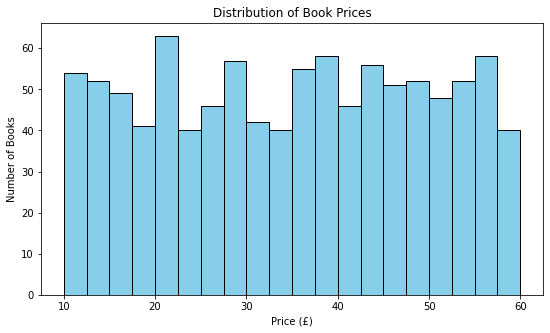

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Price"],
    bins=20,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

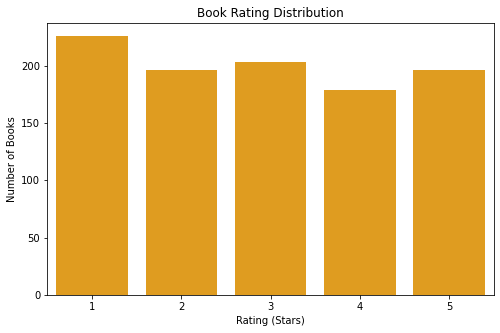

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Rating",
    color="orange"
)

plt.title("Book Rating Distribution")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Books")

plt.show()

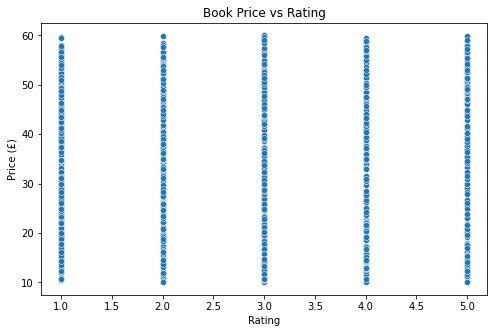

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Rating",
    y="Price"
)

plt.title("Book Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.show()

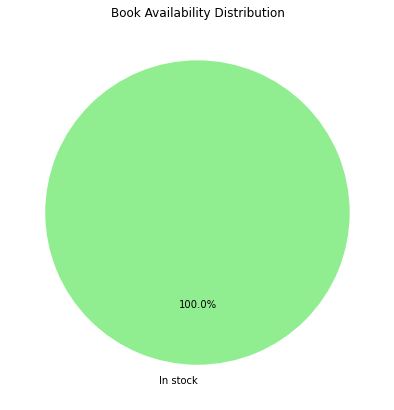

In [17]:
availability_counts = df["Availability"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    availability_counts,
    labels=availability_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["lightgreen", "tomato"]
)

plt.title("Book Availability Distribution")

plt.show()